# MEG theta power around button presses

For every button-press time and MEG sensor, this notebook computes 2–5 Hz power in the 1-second window from −0.5 to +0.5 s around the press. The MEG epochs start 2.8 s before the fractal-cue time zero, so the behavioral press times are shifted by `sens_delay` before epoching.  

values of power are averaged across each press separately for each sensor

Each press is baseline corrected against the 2–5 Hz power in the [−1s, 0s] window before that trial's cue, using 10 × log10(press power / trial baseline power).   

The final scalp map shows the mean dB change over valid presses. the 1-second window gives 1 Hz FFT bins.

import packages for file reading, MEG data handling etc.

In [15]:
import h5py
import mne 
import numpy as np
import matplotlib.pyplot as plt
import os

define parameters:

In [16]:
sub_ID = input('subject ID:')             # subject ID for participants filepath
theta_freq_band = np.array([2,5])         # frequency band edges in Hz
press_time_wind = np.array([-0.5,0.5])    # epoch window around each button press 
baseline_time_wind = np.array([-1,0])     # baseline epoch window before each trial
MEG_sens = list()                         # MEG sensor names
sens_delay = 2.8                          # offset in seconds between the task's cue-time reference and the MEG epoch start
trial_time = 14.8                         # trial duration in seconds
sfreq = 1000                              # sampling frequency in Hz
n_trials = 240                            # number of trials per participant  
n_press_slots = 5                         # number of button presses per trial 

`filename_loader` builds paths for the behavioural `.mat` files and the preprocessed FIF recording. It loads the press timings, press identities and cue durations, converts the behavioural timing values to seconds, reads the MNE epochs, identifies MEG channels and updates the sampling rate from the recording metadata.

The behavioural arrays are expected to represent trials × press slots.

In [17]:
def filename_loader(id):
    '''
    id = subject ID in 2 digit format, as a string
    '''

    # define file directories for behavioural data in beh_data folder
    subject_folder = "//rdp.arc.ucl.ac.uk/ritd-ag-project-rd01pz-dbush99/Katja Button Press Data"
    button_press_folder = '/beh_data/s'+str(id)
    BP1 = subject_folder + button_press_folder + "/behDataMEG.mat"
    BP2 = subject_folder + button_press_folder + "/targetMEG.mat"

    # define file directories for .fif MNE files in subject folder
    # folder naming convention differs for IDs that begin with 0, so handled seperately.
    if sub_ID.startswith('0'):
        spliced_id = id[1:]
        MEG_file ='/s0'+str(spliced_id)+'/Subject'+str(spliced_id)+'_spm_mne-epo'
    else:
        MEG_file ='/s'+str(id)+'/Subject'+str(id)+'_spm_mne-epo'
    epochs_file = subject_folder + MEG_file + '.fif'

    # open behavioural data file 
    with h5py.File(BP1, 'r') as f:
        timings = f['A/timing'][:]     # read timing dataset into numpy array
        presses = f['A/press'][:]      # read press identity/order codes

    # open target/cue file and read cue duration data into numpy array
    with h5py.File(BP2, 'r') as f:
        cue_duration = f['T/cueDur'][:]
    
    # transpose all arrays to trial-by-press layout expected 
    timings = timings.T               
    presses = presses.T    
    cue_duration = cue_duration.T

    # add cue duration to each press timing and converts ms to seconds
    press_times = (timings + np.tile(cue_duration,n_press_slots)) / 1000

    # read the epochs file and load its samples into epochs 
    epochs = mne.read_epochs(epochs_file, preload=True)

    # isolate all MEG sens names (start with M) from epoch data, stored in MEG_chhan
    for i in epochs.info['ch_names']:
        if i.startswith('M'):
            MEG_sens.append(i)

    # update sample frequency extracted from MNE epoch data 
    sfreq = float(epochs.info["sfreq"])

    # return outputs press times, press identity codes and the MNE epochs object
    return press_times,presses,epochs



press_times, presses, epochs = filename_loader(sub_ID)

Reading \\rdp.arc.ucl.ac.uk\ritd-ag-project-rd01pz-dbush99\Katja Button Press Data\s16\Subject16_spm_mne-epo.fif ...
    Found the data of interest:
        t =       0.00 ...   14800.00 ms
        0 CTF compensation matrices available
Reading \\rdp.arc.ucl.ac.uk\ritd-ag-project-rd01pz-dbush99\Katja Button Press Data\s16\Subject16_spm_mne-epo.fif ...
    Found the data of interest:
        t =       0.00 ...   14800.00 ms
        0 CTF compensation matrices available
Reading \\rdp.arc.ucl.ac.uk\ritd-ag-project-rd01pz-dbush99\Katja Button Press Data\s16\Subject16_spm_mne-epo.fif ...
    Found the data of interest:
        t =       0.00 ...   14800.00 ms
        0 CTF compensation matrices available
Not setting metadata
222 matching events found
No baseline correction applied
0 projection items activated


check all loaded data:  

Prints the dimensions and contents of the behavioural arrays and reports the MNE data shape/channel names. The interactive plot is a quick quality-control check of the first epoch in a few MEG channels; it is not the final scalp plot.

press times array: [[3.165 3.667 4.505 5.001 5.916]
 [3.184 3.68  4.563 5.01  5.812]
 [2.993 3.457 4.308 4.796 5.691]
 ...
 [2.804 3.74  4.232 4.939 5.339]
 [3.196 4.007 4.414 5.225 5.653]
 [3.051 3.827 4.259 5.097 5.534]]


press times shape: (240, 5)


press sequence array:[[4. 5. 2. 3. 1.]
 [4. 5. 2. 3. 1.]
 [4. 5. 2. 3. 1.]
 ...
 [4. 5. 2. 3. 1.]
 [4. 5. 2. 3. 1.]
 [4. 5. 2. 3. 1.]]


presses array shape (240, 5)
<Info | 11 non-empty values
 bads: []
 ch_names: UPPT001, UPPT002, SCLK01, BG1, BG2, BG3, BP1, BP2, BP3, BR1, ...
 chs: 2 Stimulus, 33 misc, 29 Reference Magnetometers, 273 Magnetometers, 4 EMG
 custom_ref_applied: False
 dev_head_t: MEG device -> head transform
 dig: 7 items (3 Cardinal, 4 EEG)
 file_id: 4 items (dict)
 highpass: 0.0 Hz
 lowpass: 500.0 Hz
 meas_date: unspecified
 meas_id: 4 items (dict)
 nchan: 341
 projs: []
 sfreq: 1000.0 Hz
>
MEG sensor Names: ['UPPT001', 'UPPT002', 'SCLK01', 'BG1', 'BG2', 'BG3', 'BP1', 'BP2', 'BP3', 'BR1', 'BR2', 'BR3', 'G11', 'G12', 

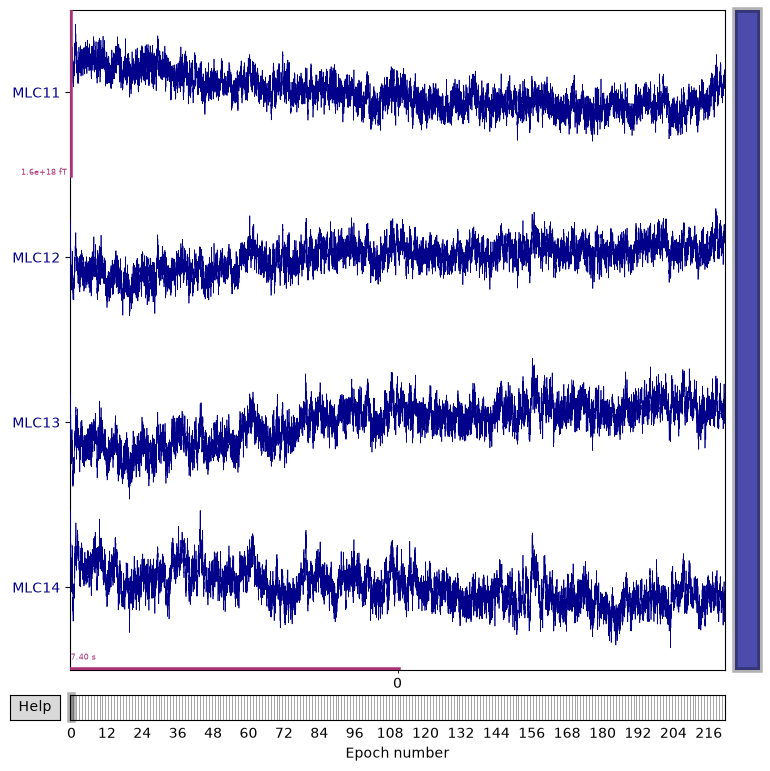

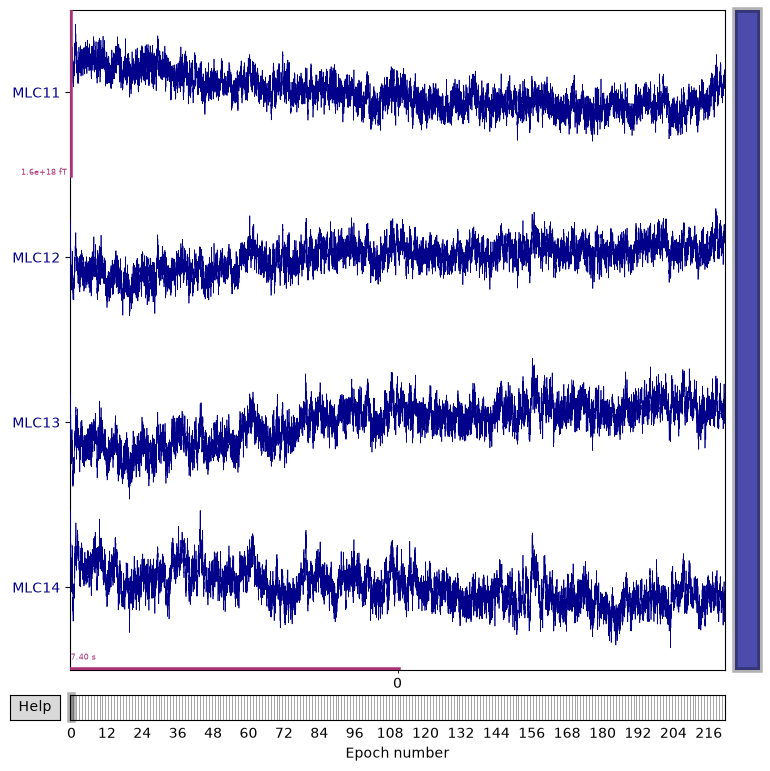

In [18]:
print(f'press times array: {press_times}')
print('\n')
print(f'press times shape: {press_times.shape}')
print('\n')
print(f'press sequence array:{presses}')
print('\n')
print(f'presses array shape {presses.shape}')

print(epochs.info)
print(f'MEG sensor Names: {epochs.info["ch_names"]}')

# plot first 4 MEG sensors from the sample data
epochs.plot(n_epochs=1,n_channels=4,picks=MEG_sens[0:4],block=True,scalings=800,show=True,)

plot signal from button press channel, labelled 'UPPT002' against button press times, to check if the channel signals align with the timings of button presses array from the beh_data folder

C:\Users\chick\AppData\Local\Temp\ipykernel_117392\450575910.py:27: UserWarning: Legend does not support handles for str instances.
A proxy artist may be used instead.
See: https://matplotlib.org/stable/users/explain/axes/legend_guide.html#controlling-the-legend-entries
  plt.legend(['Channel signal'],['Button Press'])


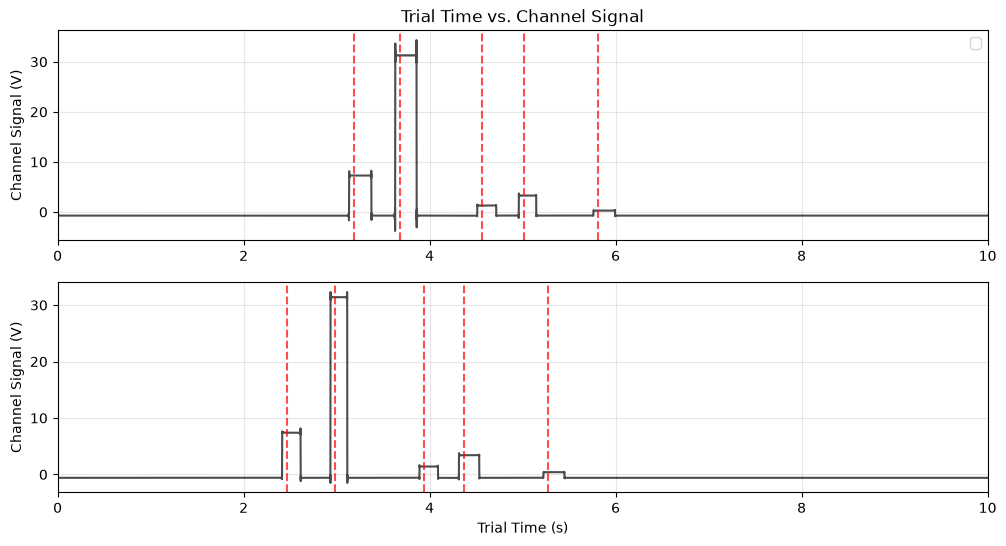

In [19]:
# isolate button press signal sens and fix time offset between the task's cue-time reference and the MEG epoch start.
uppt002_data = epochs.get_data(picks='UPPT002')[:,0,:]
uppt002_rolled = np.roll(uppt002_data, -int(sens_delay * epochs.info['sfreq']), axis=1)

# plot channel signal, with red dashed vertical lines representing button presses extracted from the 'press_times' array
def UPPT002_plot(trial1,trial2):

    plt.figure(figsize=(12, 6))
    plt.title('Trial Time vs. Channel Signal')
    plt.axis('off')

    plt.subplot(2,1,1)
    plt.plot(epochs.times, uppt002_rolled[trial1],
            color='black',
            alpha=0.7,
            )

    for idx,pt in enumerate(press_times[trial1]):
        plt.axvline(
            x=pt,
            color='r',
            linestyle='--',
            alpha=0.7,
            )
    plt.ylabel('Channel Signal (V)')
    plt.xlim([0, 10])
    plt.legend(['Channel signal'],['Button Press'])
    plt.grid(alpha=0.3,which='both',axis='both')

    plt.subplot(2,1,2)
    plt.plot(epochs.times, uppt002_rolled[trial2],
            color='black',
            alpha=0.7,
            )

    for idx,pt in enumerate(press_times[trial2]):
        plt.axvline(
            x=pt,
            color='r',
            linestyle='--',
            alpha=0.7,
            )
    plt.xlabel('Trial Time (s)')
    plt.ylabel('Channel Signal (V)')
    plt.xlim([0, 10])
    plt.grid(alpha=0.3,which='both',axis='both')
    plt.show()

UPPT002_plot(1,7)

Creating a continuous-style Raw object:  
The input file is stored as epoched data, we need to create epochs around events located along a concatenated timeline of all trials. This kernel extracts the MEG channels, rearranges the array from epochs × channels × samples into channels × samples, and constructs an MNE `RawArray`.

The concatenation places trials end-to-end so that the subsequent trial offsets based on `trial_time` correspond to that arrangement.

In [20]:
# extract shape of epochs object, isolating MEG sensor
MEG_data = epochs.get_data(picks=MEG_sens)
n_epochs, n_channels, n_times = MEG_data.shape

# update trial time with the actual number of samples in each stored epoch for trial offsets.
trial_time = n_times / sfreq

# reshape data to create raw object
MEG_data = MEG_data.transpose(1, 0, 2).reshape(n_channels, n_epochs * n_times)

# Keep the sensor geometry from the loaded FIF file for topomap plotting.
meg_picks = mne.pick_channels(epochs.info["ch_names"], include = MEG_sens)

# create channel metadata
info = mne.pick_info(epochs.info, meg_picks, copy=True)

# warap contcatenated samples in an MNE raw array
raw = mne.io.RawArray(MEG_data, info, verbose=False)

Shift press times into the concatenated timeline:  

The behavioural press times are relative to individual trials. `press_time_flattener` adds the cumulative trial offset to each trial's press times so each press is represented in the single concatenated timeline. It also creates one baseline/cut-off event per trial, offset by `sens_delay`.

Non-finite press times are removed.

In [21]:
def press_time_flattener(press_times):
    '''
    press_times = press times array (np array in shape [n_trials,n_presses])
    '''


    # checks shape of press times array, and ensures the shape matches the number of trials
    press_times = np.asarray(press_times, dtype=float)
    if press_times.ndim != 2:
        raise ValueError(f"Expected a trials-by-presses array, got shape {press_times.shape}")
    if press_times.shape[0] != n_epochs:
        raise ValueError(
            f"Behavior has {press_times.shape[0]} trials but the MEG file has {n_epochs} epochs"
        )


    # update values for number of trials and presses per trial from press times array
    n_trials, n_press_slots = press_times.shape

    # define trial offsets array, with each trial of length trial_time in seconds
    trial_offsets = np.arange(n_trials, dtype=float) * trial_time

    # Stored MEG epochs begin sens_delay seconds before zero 
    # shifts press times by trial offsets, stores new press time values in press_times_shifted
    press_times_shifted = press_times + sens_delay + trial_offsets[:, None]

    # define trial cutoff times for epoching of trials
    trial_cutoff_times = sens_delay + trial_offsets

    # keep only finite timestamps; NaN values cannot be used as event times 
    valid = np.isfinite(press_times_shifted)

    # repeats trial number across each trials press slots, making a matrix with each press labelled with it's trial index. keeps only entries marked True in 'valid' 
    press_trial_indices = np.broadcast_to(
        np.arange(n_trials)[:, None], (n_trials, n_press_slots)
    )[valid]

    print(f"Removed {(~valid).sum()} missing/non-finite press times")
    
    # return individual press event times and trial event times, along with trial index for each valid press slot
    return press_times_shifted[valid], trial_cutoff_times, press_trial_indices


press_times_shifted, trial_cutoff_times, press_trial_indices = press_time_flattener(press_times)

ValueError: Behavior has 240 trials but the MEG file has 222 epochs

Convert event times to MNE epochs:  
 
`epochs_maker` converts event times from seconds to sample indices, creates the three-column event array to make an MNE EpochsArray, and extracts the requested time window around every event. The press epochs span −0.5 to +0.5s; the baseline epochs span −1 to 0 s around the trial cut-off event.

`baseline=None` means MNE does not subtract a voltage baseline from the waveform. Baseline correction is performed later on the power estimates using a log ratio.

In [ ]:
def epochs_maker(r, events, wind, name):
    '''
    r = raw object
    events = event times in seconds
    wind = epoch window, as a list with start and stop times in seconds
    name = name of epoch array made
    '''
    
    # convert event times in seconds into integer sample indices
    samples = np.rint(np.asarray(events, dtype=float) * sfreq).astype(int)

    # MNE event rows with columns:
    # [sample_index, previous_event_value, event_code]
    # event labels are not used, so use values of 0 for final 2 columns
    event_array = np.column_stack([
        samples,
        np.zeros(len(samples), dtype=int),
        np.ones(len(samples), dtype=int),
    ])

    # extract an epoch around each sample index from the raw object
    epoch = mne.Epochs(
        r,
        event_array,
        event_id={"event": 1},               # label event id's as 'event'
        tmin=float(wind[0]),                 # epoch start relative to event in seconds
        tmax=float(wind[1]) - 1.0 / sfreq,   # epoch end relative to event in seconds
        baseline=None,                       # Do not baseline-correct the voltage waveform here.
        preload=True,
        verbose=False,
    )

    # print basic metadata for quality check of epoch objects
    print(f"{name} epochs object info:")
    print(epoch.info)

    # return extracted epochs for spectral analysis
    return epoch


press_epochs = epochs_maker(raw, press_times_shifted, press_time_wind, "press")
baseline_epochs = epochs_maker(raw, trial_cutoff_times, baseline_time_wind, "baseline")


press epochs object info:
<Info | 11 non-empty values
 bads: []
 ch_names: MLC11, MLC12, MLC13, MLC14, MLC15, MLC16, MLC17, MLC21, MLC22, ...
 chs: 273 Magnetometers
 custom_ref_applied: False
 dev_head_t: MEG device -> head transform
 dig: 7 items (3 Cardinal, 4 EEG)
 file_id: 4 items (dict)
 highpass: 0.0 Hz
 lowpass: 500.0 Hz
 meas_date: unspecified
 meas_id: 4 items (dict)
 nchan: 273
 projs: []
 sfreq: 1000.0 Hz
>
baseline epochs object info:
<Info | 11 non-empty values
 bads: []
 ch_names: MLC11, MLC12, MLC13, MLC14, MLC15, MLC16, MLC17, MLC21, MLC22, ...
 chs: 273 Magnetometers
 custom_ref_applied: False
 dev_head_t: MEG device -> head transform
 dig: 7 items (3 Cardinal, 4 EEG)
 file_id: 4 items (dict)
 highpass: 0.0 Hz
 lowpass: 500.0 Hz
 meas_date: unspecified
 meas_id: 4 items (dict)
 nchan: 273
 projs: []
 sfreq: 1000.0 Hz
>


Estimate 2–5 Hz band power

`mean_band_power` calculates a Hann-windowed, one-sided power spectral density for every epoch and sensor, then integrates the spectral density between 2 and 5 Hz.


1. `get_data` obtains data in epoch × sensor × time order.
2. The function checks that each epoch is exactly one second long.
3. Subtracting the epoch mean to remove the DC component.
4. The Hann taper reduces spectral leakage caused by analysing a finite time segment.
5. The real FFT transforms each time series to frequency space.
6. The squared FFT magnitude, with normalisation and one-sided-spectrum scaling, estimates power spectral density.
7. `rfftfreq` returns the frequency associated with each FFT bin. For a 1-second epoch, the bin spacing is 1 Hz.
8. The selected bins from 2 through 5 Hz are integrated using trapezoidal integration.

This returns one band-power value per epoch and sensor. It is not a time-frequency map; it summarises the entire one-second window.

Retained button presses: 1199
theta_db_by_press shape (presses, sensors): (1199, 273)


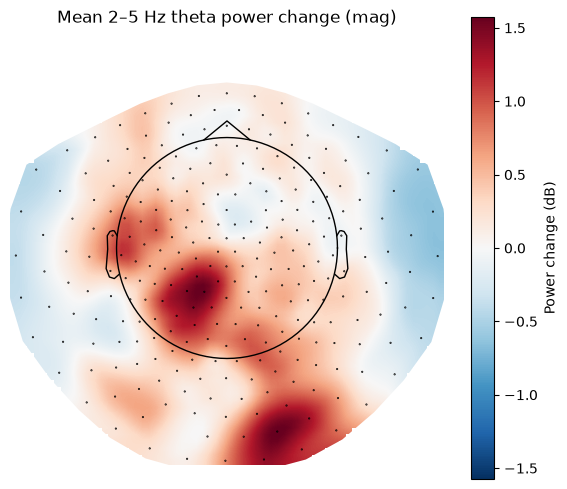

In [ ]:
def mean_band_power(epochs, band):

    # x of shape: (number of epochs, number of selected MEG sensors, samples).
    x = epochs.get_data(picks=MEG_sens)

    # Sampling frequency and Number of time samples in each epoch.
    sfreq = float(epochs.info["sfreq"])
    n_times = x.shape[-1]

    # The implementation is designed for exactly 1-second windows.
    # check if the window is 1 second long
    if not np.isclose(n_times / sfreq, 1.0):
        raise ValueError(
            f"Expected a 1-second epoch, got {n_times / sfreq:.6f} seconds"
        )

    # Hann window: taper the edges of each epoch to reduce spectral leakage. #
    # (basically makes signal from edges of epoch influence the power calculation less, due to analysing a finite time segment)
    window = np.hanning(n_times)

    # Remove the mean separately from every epoch/sensor time series.
    x = x - x.mean(axis=-1, keepdims=True)

    # multiplies each time series by the hann window, then calculates
    # the real FFT converting the signal from the time to frequency domains
    # rfft returns a frequency components of the signals as an array in shape: (epochs, sensors, frequency bins), stored in fft
    # axis = -1 ensures the transform is along the time domain
    fft = np.fft.rfft(x * window, axis=-1)

    # Convert squared FFT magnitude into a normalised power spectral density.
    # squaring the absolute value of fft gives the spectral power as signal^2 / Hz
    psd = (np.abs(fft) ** 2) / (sfreq * np.sum(window ** 2))

    # generate frequency value for every FFT bin
    # d is the time interval between samples
    freqs = np.fft.rfftfreq(n_times, d=1.0 / sfreq)

    # boolean mask to select frequencies in the band
    in_band = (freqs >= band[0]) & (freqs <= band[1])
 
    # keep only PSD values and frequency values in the requested band, keeping epoch and sensor dimensions
    band_psd = psd[..., in_band]
    band_freqs = freqs[in_band]

    # calculate total power within frequency band using trapezoidal rule
    # return the value of the total power as an output array in the shape (epoch, sensors)
    return np.sum(
        0.5 * (band_psd[..., 1:] + band_psd[..., :-1]) * np.diff(band_freqs),
        axis=-1,
    )


# calculate 2-5 Hz power for button press epoch
theta_power_by_press = mean_band_power(press_epochs, theta_freq_band)

# calculate the 2-5 Hz power for every trial baseline epoch
theta_power_baseline = mean_band_power(baseline_epochs, theta_freq_band)

# store each trials baseline power in an array in shape (m_trials, n_sensors), stored in theta_baseline_by_trial
theta_baseline_by_trial = np.full(
    (len(trial_cutoff_times), len(MEG_sens)), np.nan, dtype=float
)

# MNE selection attribute records which original event each epoch came from, using it to 
# put baseline power into the corresponding trial row 
theta_baseline_by_trial[baseline_epochs.selection] = theta_power_baseline


# map press epoch into their original trials and retrieve baseline power for the trial
press_trial_ids = press_trial_indices[press_epochs.selection]
theta_baseline_for_press = theta_baseline_by_trial[press_trial_ids]


# checks which presses have a finite baseline power
# removes any presses without usable baseline values 
has_baseline = np.isfinite(theta_baseline_for_press).any(axis=1)
theta_power_by_press = theta_power_by_press[has_baseline]
theta_baseline_for_press = theta_baseline_for_press[has_baseline]
press_trial_ids = press_trial_ids[has_baseline]
press_times_used = press_times_shifted[press_epochs.selection][has_baseline]


# stop script if no press epochs were able to be matched to a baseline
if len(theta_power_by_press) == 0:
    raise RuntimeError("No button presses have both a valid press epoch and trial baseline")



# Log-ratio baseline correction, in dB, for all presses and MEG sensors.
theta_db_by_press = np.full(theta_power_by_press.shape, np.nan, dtype=float)

# identifies power pairings for which calculation is valid (finite positive powers)
valid_power = (
    np.isfinite(theta_power_by_press)
    & np.isfinite(theta_baseline_for_press)
    & (theta_power_by_press > 0)
    & (theta_baseline_for_press > 0)
)

# make ratio array with 1s, meaning 0dB
power_ratio = np.ones_like(theta_power_by_press)

# calculate press power divided by matching trial baseline power, excluding
# invalid entries
np.divide(
    theta_power_by_press,
    theta_baseline_for_press,
    out=power_ratio,
    where=valid_power,
)

# convert power ratio into dB using 10 * log10(ratio)
theta_db_by_press[valid_power] = 10.0 * np.log10(power_ratio[valid_power])

# count the number of valid press numbers available for each sensor
sensor_counts = np.isfinite(theta_db_by_press).sum(axis=0)

# calculate the mean baseline corrected power change for each sensor, ignoring NaNs
# returns average power array in shape (n_sensors)
theta_db_mean = np.divide(
    np.nansum(theta_db_by_press, axis=0),
    sensor_counts,
    out=np.full(len(MEG_sens), np.nan),
    where=sensor_counts > 0,
)

# print diagnostic info to check number of retained presses 
# and to confirm the shape of the dimensions of the baseline correction
print(f"Retained button presses: {len(press_times_used)}")
print(f"theta_db_by_press shape (presses, sensors): {theta_db_by_press.shape}")




# Plot one topomap for each MEG sensor type (e.g. grad or mag).
sensor_types = [mne.channel_type(info, idx) for idx in range(len(MEG_sens))]
for sensor_type in sorted(set(sensor_types)):
    picks = np.array(
        [idx for idx, kind in enumerate(sensor_types) if kind == sensor_type],
        dtype=int,
    )
    sensor_info = mne.pick_info(info, picks, copy=True)
    fig, ax = plt.subplots(figsize=(7, 6))
    image, _ = mne.viz.plot_topomap(
        theta_db_mean[picks],
        sensor_info,
        ch_type=sensor_type,
        axes=ax,
        cmap="RdBu_r",
        contours=0,
        show=False,
    )
    ax.set_title(f"Mean 2–5 Hz theta power change ({sensor_type})")
    fig.colorbar(image, ax=ax, label="Power change (dB)")

plt.show()